# GOES ABI area query

Satellite **pictures of the clouds** and calibrated **cloud products** for a circle of radius `RADIUS_KM` around a lat/lon, over a UTC time range. Everything is read straight from NOAA's public AWS buckets (`noaa-goes18` = GOES-West, `noaa-goes19` = GOES-East), the same ABI files CIRA SLIDER shows.

1. **Satellite images:** RGB composites such as true colour, cloud phase and IR clouds, one picture per scan (every 5 min on CONUS/PACUS). They are drawn north-up around your point with the circle marked, and saved as PNGs plus an animated GIF.
2. **Cloud products (numbers):** cloud mask, cloud-top height, phase and so on, on the native ABI pixel grid inside the circle. They are saved as NetCDF, with a CSV of per-scan statistics such as cloud fraction.

Every frame carries its exact scan start (`time`) and end (`time_end`) in UTC. Logic lives in [src/goes_query.py](src/goes_query.py). **Kernel:** the `mapping` conda env.

In [25]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
sys.path.insert(0, str(Path("src").resolve()))
import goes_query as gq

pd.set_option("display.max_colwidth", 90)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Settings

* **Satellite**: `goes18` = GOES-West (137.2°W), `goes19` = GOES-East (75.2°W). Use whichever sees your point at the lower view angle.
* **Sector**: `"C"` = CONUS/PACUS every 5 min. `"F"` = full disk every 10 min. `"M1"`/`"M2"` = 1-min mesoscale boxes, which move around.
* **Daylight**: visible composites (`true_color`, `cloud_phase`, …) are black at night. Use `colorized_ir_clouds`, `C13` or `night_microphysics` then.
* **Cache**: every processed scan is saved under `output/cache/`. Re-running the same site, radius/view and variables loads those scans instead of fetching them, so only new scans are downloaded. Pass `cache=None` to any fetch to force a fresh read, or delete `output/cache/`.


In [ ]:
LAT, LON   = 52.82457466754165, -110.88594474303841      # centre (deg)  <-- set your site
RADIUS_KM  = 14                   # analysis circle; 14 km radius ≈ 600 km²

START = "2026-10-17 20:00"        # UTC   (08:30 PDT)
END   = "2026-10-17 22:00"        # UTC, inclusive (scan start time)

SATELLITE = "goes18"
SECTOR    = "F"
MODE      = "stream"              # or "download" to cache raw files in data/raw/

# --- satellite images ---
IMAGES  = ["true_color"]   # see the composites table below
VIEW_KM = 45                      # half-width of each picture (the circle is drawn inside)

# --- cloud products (numbers) ---
PRODUCTS = ["cloud_mask", "cloud_top_height", "cloud_top_phase"]
DATASETS = {"imagery": ["C02", "C07", "C13"]}   # optional per-product variable overrides

OUT_DIR = "output"

# 0. Quick check (run this first)

Reads only one or two small files (~15 s) and reports:

- whether the point is inside the sector, or which satellite or sector to use instead;
- the viewing angle, the real pixel size at your site and how many pixels fall inside the circle;
- the sun elevation over the range, i.e. whether the visible composites will be black;
- for every image and product: scan count, first and last scan, the largest gap, and a rough runtime estimate;
- one preview picture (visible in daylight, IR at night) with your circle drawn.

If anything shows ✗, fix the settings before running sections 1 and 2.

Query: noaa-goes18 sector F, (52.82457466754165, -110.88594474303841) r=14 km, 2026-10-17 20:00:00 → 2026-10-17 22:00:00 UTC (2.0 h)



/opt/miniconda3/envs/mapping/lib/python3.12/site-packages/pyproj/crs/crs.py:1295: UserWarning: You will likely lose important projection information when converting to a PROJ string from another format. See: https://proj.org/faq.html#what-is-the-best-format-for-describing-coordinate-reference-systems
  proj = self._crs.to_proj4(version=version)


✓ Point is inside the F sector (sub-satellite longitude -137.0°).
  Viewing zenith angle 65° (oblique: pixels stretched, parallax large).
  Actual pixel size here: 2 km IR ≈ 2.6 × 4.9 km (0.5 km visible ≈ 0.66 × 1.24 km).
  56 IR pixels (~896 visible C02 pixels) fall inside the 14 km circle.
  Parallax: a cloud top at h km appears ~2.1·h km away from the satellite.

  Sun elevation over the range: 18° … 27° → daylight throughout.

Estimated full run: ~4 min for images ±120 km and products r=14 km (rough; scales with area, network-dependent).


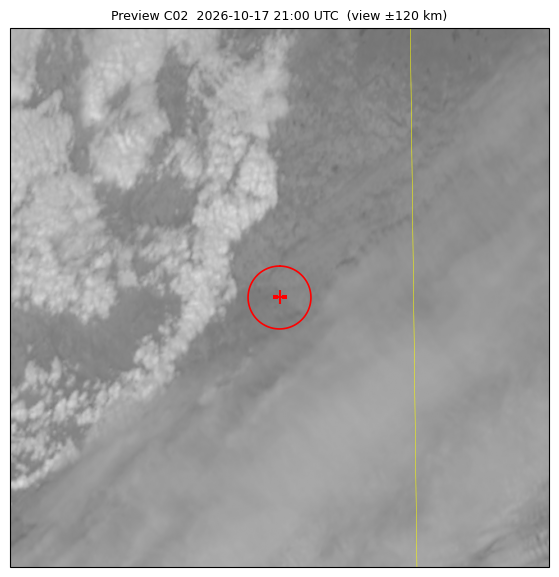

,scans,files,first_scan,last_scan,max_gap_min,full_file_mb,note,image_px,image_mpx,est_s_per_scan,est_minutes
item,,,,,,,,,,,
image: true_color,12,36,2026-10-17 20:00:21.300,2026-10-17 21:50:21.100,10.0,7300.3,,960×960,2.8,19.2,2.7
image: colorized_ir_clouds,12,12,2026-10-17 20:00:21.300,2026-10-17 21:50:21.100,10.0,286.8,,240×240,0.2,2.5,0.4
product: cloud_mask,12,12,2026-10-17 20:00:21.300,2026-10-17 21:50:21.100,10.0,284.9,,,0.0,3.0,0.4
product: cloud_top_height,12,12,2026-10-17 20:00:21.300,2026-10-17 21:50:21.100,10.0,367.0,,,0.0,3.0,0.4
product: cloud_top_phase,12,12,2026-10-17 20:00:21.300,2026-10-17 21:50:21.100,10.0,42.9,,,0.0,3.0,0.4


In [4]:
check = gq.quick_check(LAT, LON, RADIUS_KM, START, END, images=IMAGES, products=PRODUCTS,
                       sector=SECTOR, satellite=SATELLITE, view_km=VIEW_KM, datasets=DATASETS)
check

# 1. Satellite images

Available composites (any other satpy composite name, or a single channel such as `C02`/`C13`, also works):

In [6]:
gq.composites_table()

,channels,description
composite,,
true_color,C01 C02 C03,"Day: what the eye sees, Rayleigh-corrected, 0.5 km"
natural_color,C02 C03 C05,"Day: water clouds white, ice clouds/snow cyan"
cloud_phase,C02 C05 C06,Day: liquid (white/yellow) vs ice (green/blue) tops
day_cloud_type,C02 C04 C05,"Day: cloud type (cirrus, low, thick ice)"
day_microphysics_abi,C03 C06 C13,Day: cloud particle size / phase
colorized_ir_clouds,C13,"Day & night: 10.3 µm IR, cold tops coloured"
C13,C13,"Day & night: 10.3 µm clean IR window, greyscale"
C02,C02,"Day: 0.64 µm red visible, 0.5 km, greyscale"
night_microphysics,C07 C13 C15,Night: low cloud and fog


In [7]:
images = {}
for comp in IMAGES:
    print(f"--- {comp}")
    images[comp] = gq.fetch_images(LAT, LON, START, END, comp, view_km=VIEW_KM, radius_km=RADIUS_KM,
                                   sector=SECTOR, satellite=SATELLITE, mode=MODE, workers=4)
    print(f"{images[comp].sizes['time']} scans, {images[comp].sizes['x']}×{images[comp].sizes['y']} px")

--- true_color


  0%|          | 0/12 [00:00<?, ?scan/s]

12 scans, 640×640 px
--- colorized_ir_clouds


  0%|          | 0/12 [00:00<?, ?scan/s]

12 scans, 160×160 px


Latest scan of each composite. Pass `t=` an index or a timestamp to pick another.

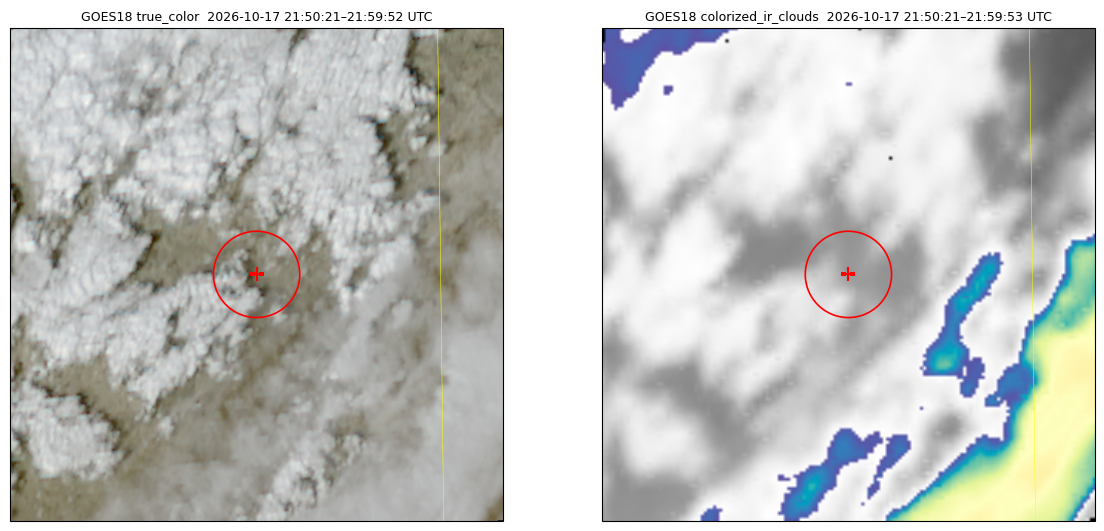

In [8]:
fig, axes = plt.subplots(1, len(images), figsize=(7 * len(images), 7), squeeze=False,
                         subplot_kw={"projection": gq._image_projection(next(iter(images.values())))})
for ax, img in zip(axes.flat, images.values()):
    gq.plot_image(img, t=-1, ax=ax)
plt.show()

### More natural colours

ABI has no green band, so every true-colour image synthesises green, and satpy's `true_color` makes dry land olive-grey. `true_color_reproduction` (JMA's colour-matrix method) gets the land hue much closer to CIRA/SLIDER. A gamma above 1 then darkens its mid-tones.

`gq.adjust_image(img, saturation, contrast, gamma)` changes only the display. The cached scans are untouched, so you can tune it freely. It works on any picture.

In [ ]:
nat = gq.fetch_images(LAT, LON, START, END, "true_color_reproduction", view_km=VIEW_KM, radius_km=RADIUS_KM,
                      sector=SECTOR, satellite=SATELLITE, mode=MODE)      # ~2× slower than true_color
nat = gq.adjust_image(nat, saturation=1.1, gamma=1.5)                     # tune to taste
gq.plot_image(nat, t=-1)
plt.show()

Evolution over the time range:

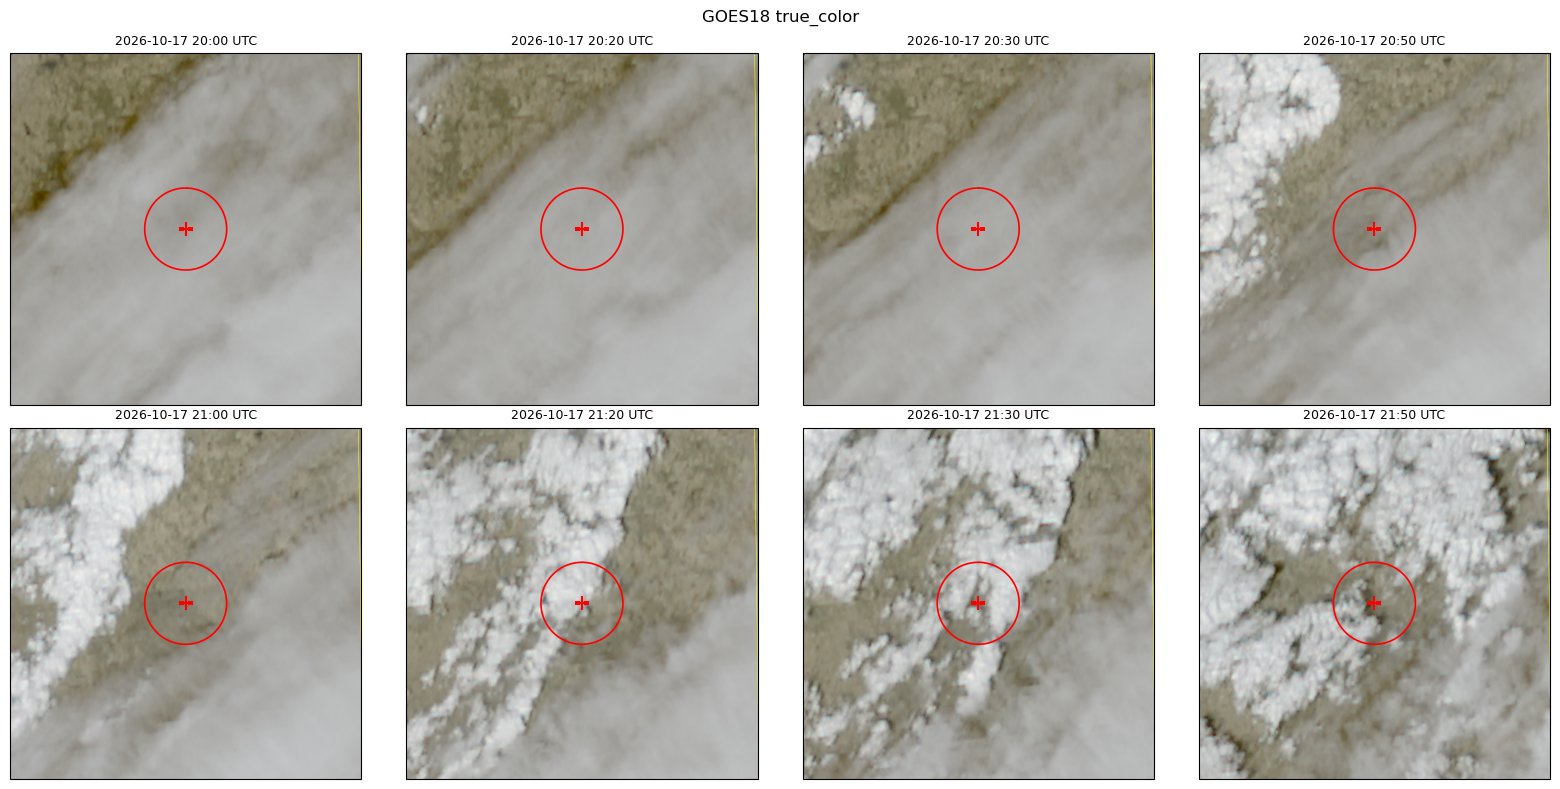

In [51]:
gq.plot_images(images[IMAGES[0]], n=8)
plt.show()

Save one annotated PNG per scan (named by scan start, UTC) plus `animation.gif`:

In [9]:
for comp, img in images.items():
    print(comp, "→", gq.save_images(img, f"{OUT_DIR}/images"))

true_color → output/images/goes18_true_color_F_52.825_-110.886_v80km
colorized_ir_clouds → output/images/goes18_colorized_ir_clouds_F_52.825_-110.886_v80km


### Single channel (e.g. C07)

Any ABI channel `C01`–`C16` can be shown on its own, without re-running the composites above. IR channels (C07–C16) are drawn **white = cold, black = hot**; visible channels (C01–C06) get a square-root stretch. See the README's *ABI channels* table for what each band shows.

IR brightness is stretched to each scan's own range, so compare temperatures with the numbers in section 2, not the shades.

In [ ]:
CHANNEL = "C07"   # 3.9 µm shortwave IR: hot spots/fires, night fog. Try "C13" for clean IR temperature.

chan = gq.fetch_images(LAT, LON, START, END, CHANNEL, view_km=VIEW_KM, radius_km=RADIUS_KM,
                       sector=SECTOR, satellite=SATELLITE, mode=MODE, workers=4)
gq.plot_image(chan, t=-1)
plt.show()
gq.plot_images(chan, n=8)
plt.show()
print("saved to", gq.save_images(chan, f"{OUT_DIR}/images"))

  0%|          | 0/12 [00:00<?, ?scan/s]

# 2. Cloud products (numbers inside the circle)

Values stay on the **native ABI fixed grid**. Each scan is cropped around your point and nothing is interpolated. The output has 2-D `lat`/`lon`, `distance_km` and an `in_radius` mask.

In [36]:
gq.catalog_table()

,bucket_folder,variables,sectors,res_km,description
product,,,,,
cloud_mask,ABI-L2-ACM{C|F|M},"BCM, ACM, Cloud_Probabilities",CFM,2,"Clear-sky mask: BCM binary cloud mask, ACM 4-level mask, cloud probability"
cloud_top_height,ABI-L2-ACHA2KM{C|F|M},HT,CFM,2,"Cloud-top height [m], 2 km"
cloud_top_height_10km,ABI-L2-ACHA{C|F|M},HT,CFM,10,"Cloud-top height [m], 10 km"
cloud_top_temperature,ABI-L2-ACHT{C|F|M},TEMP,FM,2,Cloud-top temperature [K]
cloud_top_phase,ABI-L2-ACTP{C|F|M},Phase,CFM,2,Cloud-top phase: clear / liquid / supercooled / mixed / ice
cloud_top_pressure,ABI-L2-CTP{C|F|M},PRES,CF,10,"Cloud-top pressure [hPa], 10 km"
cloud_optical_depth,ABI-L2-COD{C|F|M},COD,CF,2,"Cloud optical depth (C: 2 km, F: 4 km)"
cloud_particle_size,ABI-L2-CPS{C|F|M},CPS,CFM,2,Cloud particle effective radius [um]
imagery,ABI-L2-CMIP{C|F|M},"C02, C13",CFM,0.5-2,Cloud & Moisture Imagery: reflectance (C01-06) / brightness temp K (C07-16)


Preview what will be read. `size_mb` is the full file size; in `stream` mode only a small fraction of that is transferred.

In [15]:
for prod in PRODUCTS:
    files = gq.list_files(prod, START, END, sector=SECTOR, satellite=SATELLITE, datasets=DATASETS.get(prod))
    print(f"{prod:28s} {files.start_time.nunique():4d} scans  {len(files):4d} files  "
          f"{files.size_mb.sum():8.1f} MB full-file size")

cloud_mask                     12 scans    12 files     284.9 MB full-file size
cloud_top_height               12 scans    12 files     367.0 MB full-file size
cloud_top_phase                12 scans    12 files      42.9 MB full-file size


Optional: list the variables actually inside a product's files.

In [16]:
gq.inspect_product("cloud_mask", START, sector=SECTOR, satellite=SATELLITE)

noaa-goes18/ABI-L2-ACMF/2026/290/19/OR_ABI-L2-ACMF-M6_G18_s20262901930213_e20262901939522_c20262901940152.nc


,shape,units,long_name
variable,,,
BCM,"(5424, 5424)",1,ABI L2+ Clear Sky Mask
ACM,"(5424, 5424)",,(Real-Value) four level cloud mask
Cloud_Probabilities,"(5424, 5424)",,ABI Cloud Mask product Cloud Probabilities
DQF,"(5424, 5424)",1,ABI L2+ Clear Sky Mask data quality flags


In [17]:
results = {}
for prod in PRODUCTS:
    print(f"--- {prod}")
    results[prod] = gq.fetch(prod, LAT, LON, RADIUS_KM, START, END,
                             sector=SECTOR, satellite=SATELLITE, mode=MODE,
                             datasets=DATASETS.get(prod), workers=4)

ds = results[PRODUCTS[0]]
ds

--- cloud_mask


  0%|          | 0/12 [00:00<?, ?scan/s]

--- cloud_top_height


  0%|          | 0/12 [00:00<?, ?scan/s]

--- cloud_top_phase


  0%|          | 0/12 [00:00<?, ?scan/s]

<xarray.Dataset> Size: 33kB
Dimensions:              (time: 12, y: 10, x: 21)
Coordinates:
  * time                 (time) datetime64[us] 96B 2026-10-17T20:00:21.300000...
    time_end             (time) datetime64[us] 96B 2026-10-17T20:09:52.200000...
  * y                    (y) float64 80B 4.66e+06 4.658e+06 ... 4.642e+06
  * x                    (x) float64 168B 1.538e+06 1.54e+06 ... 1.578e+06
    lat                  (y, x) float32 840B 52.97 52.97 52.98 ... 52.65 52.66
    lon                  (y, x) float32 840B -111.1 -111.1 ... -110.7 -110.6
    distance_km          (y, x) float32 840B 23.82 22.19 20.76 ... 23.82 25.25
    in_radius            (y, x) bool 210B False False False ... False False
Data variables:
    BCM                  (time, y, x) float32 10kB nan nan nan ... nan nan nan
    ACM                  (time, y, x) float32 10kB nan nan nan ... nan nan nan
    Cloud_Probabilities  (time, y, x) float32 10kB nan nan nan ... nan nan nan
Attributes: (12/13)
    crs_wkt:         PROJCRS["unknown",BASEGEOGCRS["unknown",DATUM["Unknown b...
    product:         ABI-L2-ACMF
    product_key:     cloud_mask
    satellite:       noaa-goes18
    center_lat:      52.82457466754165
    center_lon:      -110.88594474303841
    ...              ...
    query_start:     2026-10-17 20:00:00
    query_end:       2026-10-17 22:00:00
    sector:          F
    source:          s3://noaa-goes18/ABI-L2-ACMF
    time_note:       time = scan start, time_end = scan end (UTC), from the f...
    n_scans_failed:  0

Save (NetCDF cube + per-scan summary CSV):

In [18]:
for prod, d in results.items():
    print(prod, gq.save(d, OUT_DIR))

cloud_mask {'netcdf': PosixPath('output/goes18_cloud_mask_F_52.825_-110.886_r14km_20261017T2000-20261017T2150.nc'), 'summary_csv': PosixPath('output/goes18_cloud_mask_F_52.825_-110.886_r14km_20261017T2000-20261017T2150_summary.csv')}
cloud_top_height {'netcdf': PosixPath('output/goes18_cloud_top_height_F_52.825_-110.886_r14km_20261017T2000-20261017T2150.nc'), 'summary_csv': PosixPath('output/goes18_cloud_top_height_F_52.825_-110.886_r14km_20261017T2000-20261017T2150_summary.csv')}
cloud_top_phase {'netcdf': PosixPath('output/goes18_cloud_top_phase_F_52.825_-110.886_r14km_20261017T2000-20261017T2150.nc'), 'summary_csv': PosixPath('output/goes18_cloud_top_phase_F_52.825_-110.886_r14km_20261017T2000-20261017T2150_summary.csv')}


### Per-scan statistics inside the circle

Flag variables give class fractions, e.g. `BCM:cloudy_or_probably_cloudy` is the cloud fraction. Continuous variables give mean/min/max/std. `*_valid_frac` is the share of in-circle pixels that have a retrieval (cloud-top height only exists where there is cloud).

In [19]:
summaries = {prod: gq.summarize(d) for prod, d in results.items()}
summaries[PRODUCTS[0]].drop(columns="time_end").round(3)

,BCM_valid_frac,BCM:clear_or_probably_clear,BCM:cloudy_or_probably_cloudy,ACM_valid_frac,ACM:clear,ACM:probably_clear,ACM:probably_cloudy,ACM:cloudy,Cloud_Probabilities_valid_frac,Cloud_Probabilities_mean,Cloud_Probabilities_min,Cloud_Probabilities_max,Cloud_Probabilities_std
time,,,,,,,,,,,,,
2026-10-17 20:00:21.300,1.0,0.000,1.000,1.0,0.0,0.000,0.000,1.000,1.0,0.998,0.988,0.999,0.002
2026-10-17 20:10:21.300,1.0,0.000,1.000,1.0,0.0,0.000,0.000,1.000,1.0,0.999,0.992,0.999,0.001
2026-10-17 20:20:21.300,1.0,0.000,1.000,1.0,0.0,0.000,0.000,1.000,1.0,0.997,0.981,0.999,0.004
2026-10-17 20:30:21.300,1.0,0.000,1.000,1.0,0.0,0.000,0.000,1.000,1.0,0.996,0.974,0.999,0.005
2026-10-17 20:40:21.300,1.0,0.000,1.000,1.0,0.0,0.000,0.000,1.000,1.0,0.995,0.947,0.999,0.010
2026-10-17 20:50:21.100,1.0,0.000,1.000,1.0,0.0,0.000,0.000,1.000,1.0,0.999,0.994,0.999,0.001
2026-10-17 21:00:21.100,1.0,0.036,0.964,1.0,0.0,0.036,0.071,0.893,1.0,0.956,0.353,1.000,0.135
2026-10-17 21:10:21.100,1.0,0.089,0.911,1.0,0.0,0.089,0.339,0.571,1.0,0.860,0.120,1.000,0.206
2026-10-17 21:20:21.100,1.0,0.000,1.000,1.0,0.0,0.000,0.018,0.982,1.0,0.998,0.896,1.000,0.014


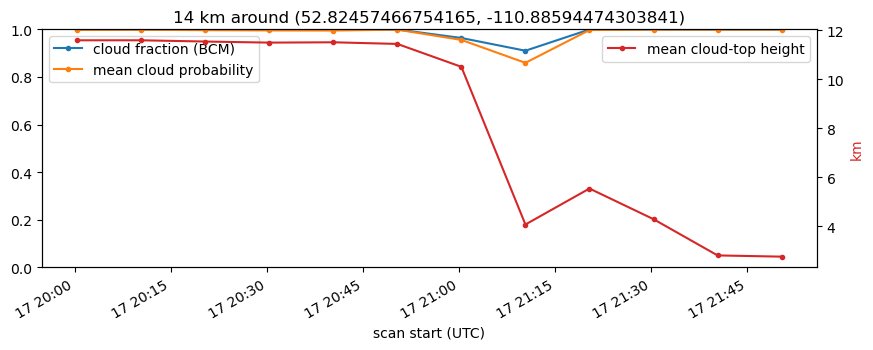

In [20]:
fig, ax = plt.subplots(figsize=(10, 3.5))
s = summaries.get("cloud_mask")
if s is not None:
    s["BCM:cloudy_or_probably_cloudy"].plot(ax=ax, marker=".", label="cloud fraction (BCM)")
    s["Cloud_Probabilities_mean"].plot(ax=ax, marker=".", label="mean cloud probability")
    ax.set_ylim(0, 1)
if "cloud_top_height" in summaries:
    ax2 = ax.twinx()
    (summaries["cloud_top_height"]["HT_mean"] / 1000).plot(ax=ax2, color="tab:red", marker=".", label="mean cloud-top height")
    ax2.set_ylabel("km", color="tab:red")
    ax2.legend(loc="upper right")
ax.set_xlabel("scan start (UTC)")
ax.legend(loc="upper left")
ax.set_title(f"{RADIUS_KM} km around ({LAT}, {LON})")
plt.show()

### Product maps

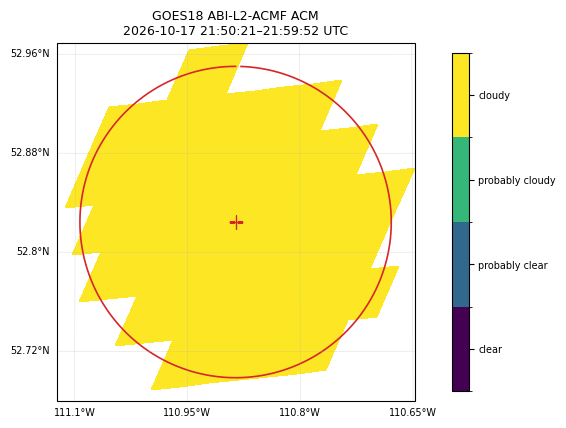

In [21]:
gq.plot_frame(results["cloud_mask"], "ACM", t=-1)
plt.show()

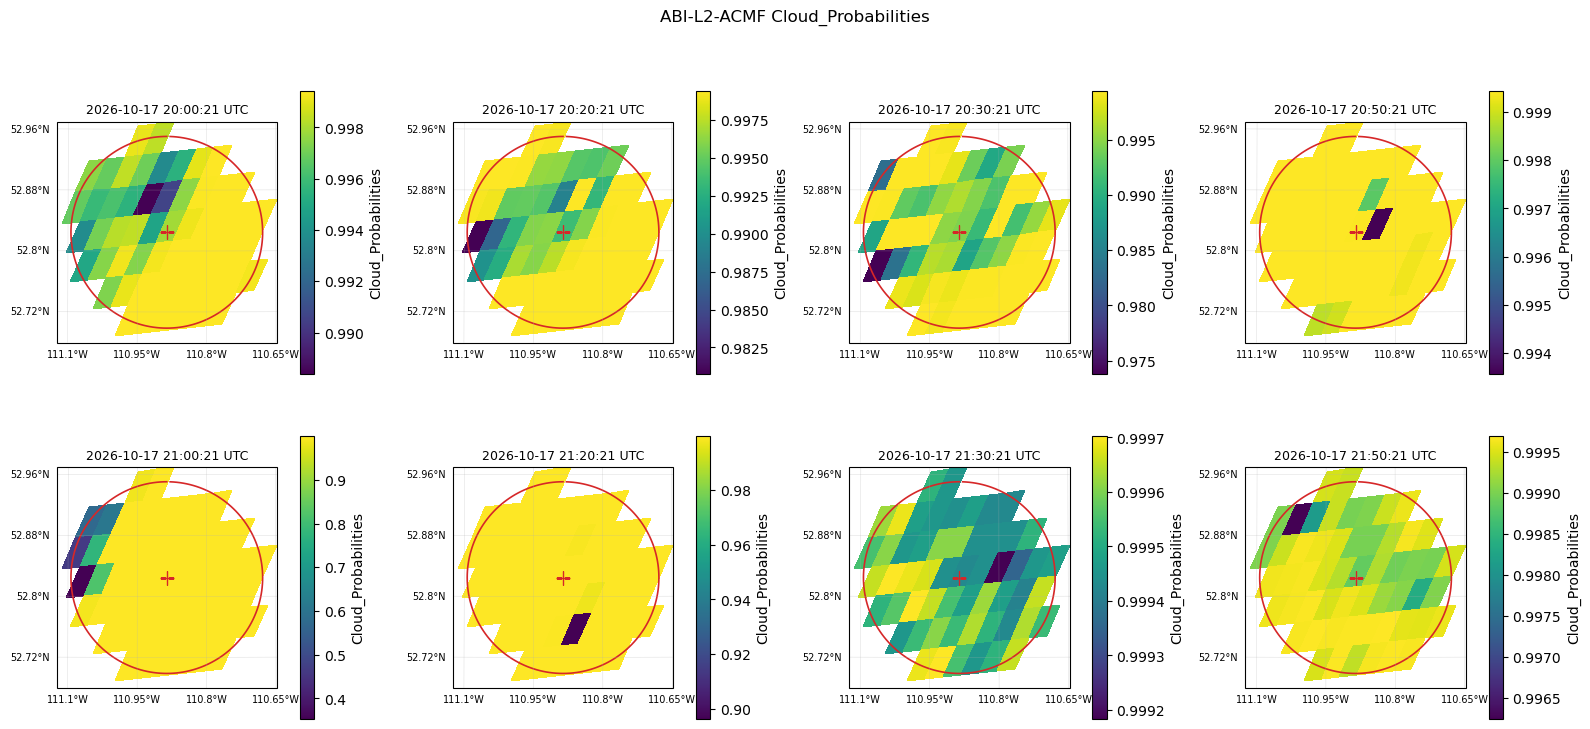

In [22]:
gq.plot_frames(results["cloud_mask"], "Cloud_Probabilities", n=8)
plt.show()

### Pick a single time / the centre pixel

`sel(..., method="nearest")` gets the scan closest to a given moment.

In [45]:
t = pd.Timestamp(START) + (pd.Timestamp(END) - pd.Timestamp(START)) / 2
snap = ds.sel(time=t, method="nearest")
print("nearest scan:", snap.time.values, "→", snap.time_end.values)

iy, ix = np.unravel_index(np.nanargmin(ds.distance_km.values), ds.distance_km.shape)
point = ds.isel(y=iy, x=ix)
print(f"centre pixel at {float(point.lat):.4f}, {float(point.lon):.4f} ({float(point.distance_km):.2f} km from target)")
point.to_dataframe()[list(ds.data_vars)].head()

nearest scan: 2026-10-17T21:00:21.100000 → 2026-10-17T21:09:51.900000
centre pixel at 52.8326, -110.8762 (1.11 km from target)


,BCM,ACM,Cloud_Probabilities
time,,,
2026-10-17 20:00:21.300,1.0,3.0,0.997901
2026-10-17 20:10:21.300,1.0,3.0,0.999275
2026-10-17 20:20:21.300,1.0,3.0,0.993567
2026-10-17 20:30:21.300,1.0,3.0,0.994514
2026-10-17 20:40:21.300,1.0,3.0,0.983037


# 3. Hot spot detection

Define your own pixel tests on the calibrated IR values (e.g. C07 − C13) and draw the flagged pixels over the true-colour pictures, next to NOAA's fire detections.

Each flagged pixel is drawn as its **real footprint**. At oblique views that's a slanted parallelogram several km across, so the heat source can be anywhere inside it.

Rules of thumb (see the README, *Heat vs cloud*):
- **Real heat:** C07 much hotter than its surroundings, C13 near a normal surface temperature (not a cold cloud top), and it persists across scans.
- **Daytime cloud artifact:** large C07 − C13 from reflected sunlight, but a cold C13 and C07 no hotter than nearby pixels.

The data is fetched over the whole picture (`radius = VIEW_KM`, nothing masked), so flags can appear anywhere in the image.

In [26]:
# Calibrated values on the native 2 km grid, covering the whole picture
ir = gq.fetch("imagery", LAT, LON, VIEW_KM, START, END, sector=SECTOR, satellite=SATELLITE, mode=MODE,
              datasets=["C07", "C13"], mask_outside=False)
fi = gq.fetch("fire", LAT, LON, VIEW_KM, START, END, sector=SECTOR, satellite=SATELLITE, mode=MODE,
              mask_outside=False)
d = xr.merge([ir[["C07", "C13"]], fi[["Mask", "Power"]]], join="inner", compat="override")
d

ABI-L2-CMIPF: 12 of 12 scans loaded from cache (output/cache/v1/data/goes18_ABI-L2-CMIPF_52.82457_-110.88594_r80km_C07+C13)
ABI-L2-FDCF: 12 of 12 scans loaded from cache (output/cache/v1/data/goes18_ABI-L2-FDCF_52.82457_-110.88594_r80km_Mask+Power+Temp+Area)


<xarray.Dataset> Size: 867kB
Dimensions:      (time: 12, y: 44, x: 96)
Coordinates:
  * time         (time) datetime64[ns] 96B 2026-10-17T20:00:21.300000 ... 202...
    time_end     (time) datetime64[ns] 96B 2026-10-17T20:09:53.300000 ... 202...
  * y            (y) float64 352B 4.694e+06 4.692e+06 ... 4.61e+06 4.608e+06
  * x            (x) float64 768B 1.464e+06 1.466e+06 ... 1.652e+06 1.654e+06
    lat          (y, x) float32 17kB 53.58 53.58 53.58 ... 52.07 52.07 52.07
    lon          (y, x) float32 17kB -112.1 -112.0 -112.0 ... -109.7 -109.7
    distance_km  (y, x) float32 17kB 115.8 114.2 112.7 ... 114.4 116.0 117.6
    in_radius    (y, x) bool 4kB False False False False ... False False False
Data variables:
    C07          (time, y, x) float32 203kB 289.3 286.9 284.1 ... 282.3 279.3
    C13          (time, y, x) float32 203kB 279.4 269.6 262.9 ... 266.6 260.5
    Mask         (time, y, x) float32 203kB 100.0 200.0 200.0 ... 200.0 200.0
    Power        (time, y, x) float32 203kB nan nan nan nan ... nan nan nan nan
Attributes: (12/13)
    crs_wkt:         PROJCRS["unknown",BASEGEOGCRS["unknown",DATUM["Unknown b...
    product:         ABI-L2-CMIPF
    product_key:     imagery
    satellite:       noaa-goes18
    center_lat:      52.82457466754165
    center_lon:      -110.88594474303841
    ...              ...
    query_start:     2026-10-17 20:00:00
    query_end:       2026-10-17 22:00:00
    sector:          F
    source:          s3://noaa-goes18/ABI-L2-CMIPF
    time_note:       time = scan start, time_end = scan end (UTC), from the f...
    n_scans_failed:  0

In [27]:
# ---- your rules: any boolean expression on d's variables ----------------------------
d["dT"]       = d.C07 - d.C13                        # 3.9 µm minus 10.3 µm brightness temperature
d["C07_anom"] = d.C07 - d.C07.median(("y", "x"))     # hotter than the scene's typical pixel?

my_flag   = (d.dT > 20) & (d.C07_anom > 10) & (d.C13 > 260)   # warm surface, not a cold cloud top
noaa_fire = gq.fire_pixels(d.Mask, confidence="medium")       # NOAA FDC detections, for comparison

print("my rule, pixels per scan:",
      dict(zip(pd.to_datetime(d.time.values).strftime("%H:%M"), my_flag.sum(("y", "x")).values.tolist())))
gq.flagged_pixels(my_flag, d, ["C07", "C13", "dT", "C07_anom", "Mask", "Power"])

my rule, pixels per scan: {'20:00': 41, '20:10': 13, '20:20': 44, '20:30': 135, '20:40': 173, '20:50': 108, '21:00': 10, '21:10': 0, '21:20': 1, '21:30': 8, '21:40': 6, '21:50': 3}


,time,lat,lon,distance_km,C07,C13,dT,C07_anom,Mask,Power
0,2026-10-17 20:00:21.300,53.7144,-109.5309,133.8,290.057129,268.203339,21.853790,10.228088,200.0,NaN
1,2026-10-17 20:00:21.300,53.6314,-110.1304,102.9,290.227386,267.588806,22.638580,10.398346,200.0,NaN
2,2026-10-17 20:00:21.300,53.5865,-110.2029,96.2,291.144135,268.817871,22.326263,11.315094,200.0,NaN
3,2026-10-17 20:00:21.300,53.5893,-110.1627,97.7,290.751251,264.639069,26.112183,10.922211,200.0,NaN
4,2026-10-17 20:00:21.300,53.6181,-109.7597,115.8,290.580994,268.572083,22.008911,10.751953,200.0,NaN
...,...,...,...,...,...,...,...,...,...,...
537,2026-10-17 21:40:21.100,52.7538,-110.8962,7.9,324.316742,280.186737,44.130005,35.673981,33.0,336.274658
538,2026-10-17 21:40:21.100,52.7564,-110.8574,7.8,317.546021,280.248199,37.297821,28.903259,100.0,NaN
539,2026-10-17 21:50:21.100,52.7945,-110.8668,3.6,298.897064,276.192291,22.704773,10.660309,100.0,NaN
540,2026-10-17 21:50:21.100,52.7538,-110.8962,7.9,300.075714,265.130676,34.945038,11.838959,200.0,NaN


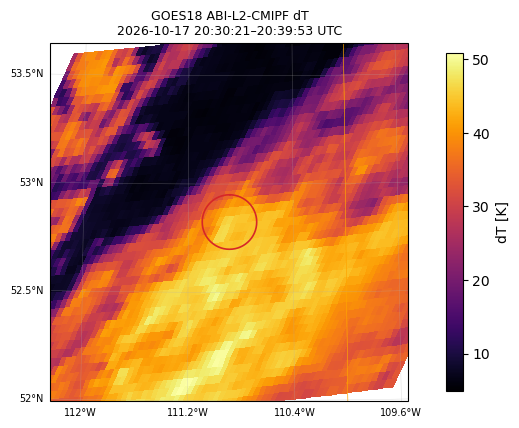

In [80]:
d["dT"] = d.C07 - d.C13
#["dT"] = d.C13
d["dT"].attrs["units"] = "K"

gq.plot_frame(d, "dT", t=3, cmap="inferno", circle_km=RADIUS_KM,
              #overlays=[dict(mask=noaa_fire, color="cyan", style="dot", label="NOAA fire")])
)
plt.show()

In [79]:
fr["fire_rgb"] = gq.fire_temperature_rgb(fr)
gq.plot_frame(fr, "fire_rgb", t=3, cmap="inferno", circle_km=RADIUS_KM,
              #overlays=[dict(mask=noaa_fire, color="cyan", style="dot", label="NOAA fire")])
)
plt.show()

NameError: name 'fr' is not defined

### Over true colour

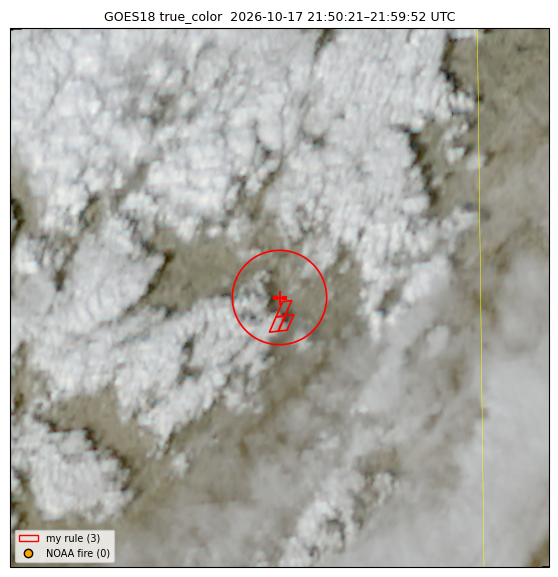

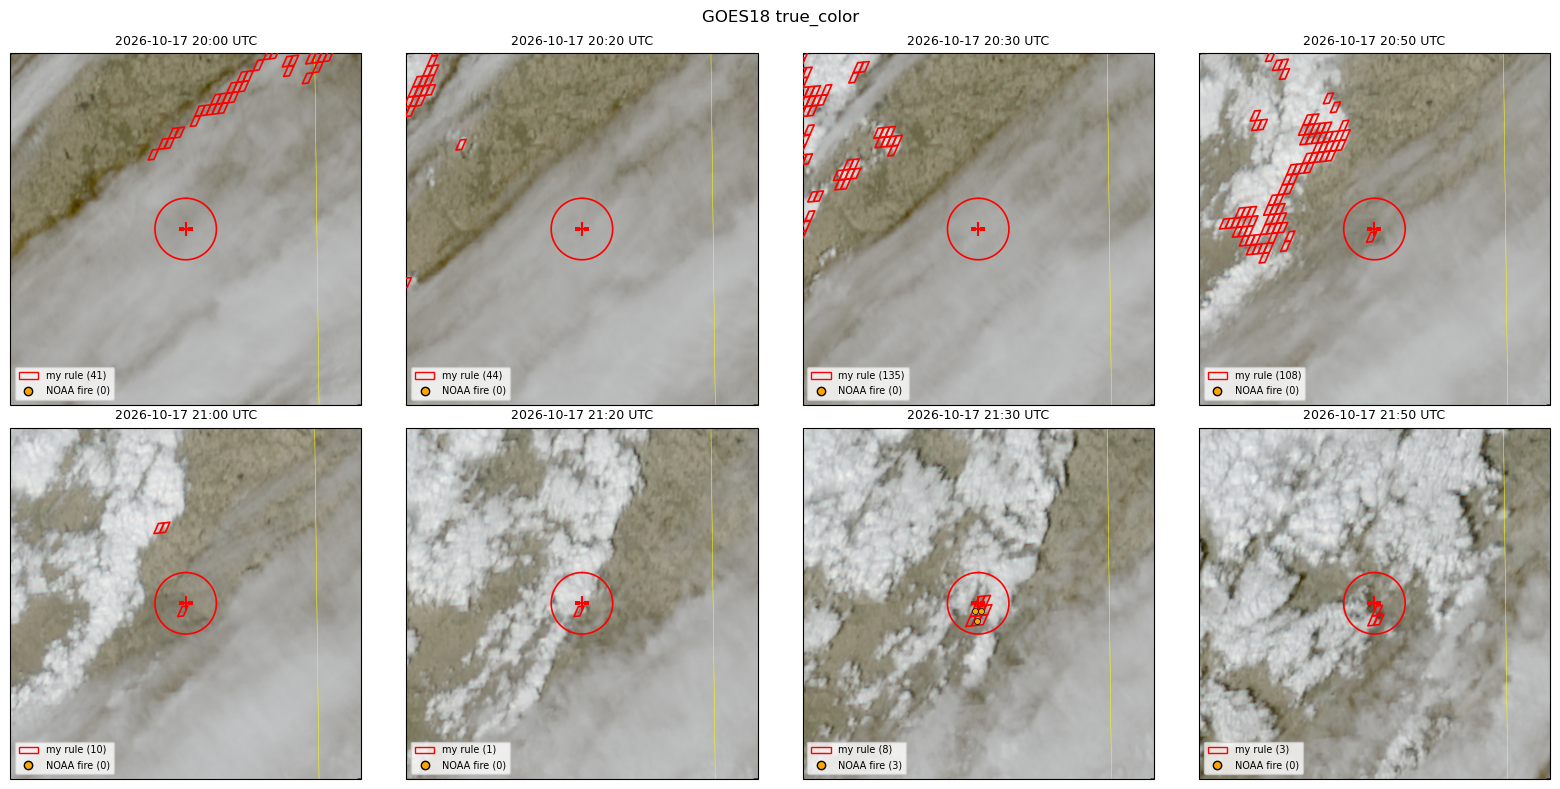

In [30]:
# True colour from section 1 if it's been run, otherwise fetch it (same VIEW_KM)
images = globals().get("images", {})
tc = images["true_color"] if "true_color" in images else gq.fetch_images(
    LAT, LON, START, END, "true_color", view_km=VIEW_KM, radius_km=RADIUS_KM,
    sector=SECTOR, satellite=SATELLITE, mode=MODE)

overlays = [dict(mask=my_flag,   color="red",    label="my rule"),                 # pixel outlines
            dict(mask=noaa_fire, color="orange", label="NOAA fire", style="dot")]  # pixel centres

T = -1   # scan to show: an index, or a time like "2026-10-17 21:30"
gq.plot_image(tc, t=T, overlays=overlays)
plt.show()
gq.plot_images(tc, n=8, overlays=overlays)
plt.show()

Plot a derived field such as C07 − C13 directly, on its native pixels. A fixed `vmin`/`vmax` keeps scans comparable.

By day, cold, sunlit clouds can show a C07 − C13 as large as a fire's, which is why the rules above also test `C07_anom` and `C13`.

In [ ]:
d["dT"].attrs["units"] = "K"
field_kw = dict(cmap="inferno", vmin=0, vmax=40, circle_km=RADIUS_KM,
                overlays=[dict(mask=noaa_fire, color="cyan", style="dot", label="NOAA fire")])
gq.plot_frame(d, "dT", t=T, **field_kw)
plt.show()
gq.plot_frames(d, "dT", n=8, **field_kw)
plt.show()

Fire Temperature RGB as a frame: the same recipe as the `cira_fire_temperature` picture, built from the calibrated C07, C06 and C05 values on native pixels, with your flags drawn on top.

Small or cool fires show red, hotter ones orange to yellow, and the most intense near white; clouds are blue/white. Use `gq.make_rgb(ds, red=(var, min, max[, gamma]), green=..., blue=...)` to build your own RGB from any variables.

In [ ]:
fr = gq.fetch("imagery", LAT, LON, VIEW_KM, START, END, sector=SECTOR, satellite=SATELLITE, mode=MODE,
              datasets=["C05", "C06", "C07"], mask_outside=False)
fr["fire_rgb"] = gq.fire_temperature_rgb(fr)        # or gq.make_rgb(fr, ("C07", 273, 333, 0.4), ("C06", 0, 100), ("C05", 0, 75))

gq.plot_frame(fr, "fire_rgb", t=T, circle_km=RADIUS_KM, overlays=overlays)
plt.show()
gq.plot_frames(fr, "fire_rgb", n=8, circle_km=RADIUS_KM, overlays=overlays)
plt.show()

Save every scan with the overlays (PNG per scan + GIF, in a `…_flags` folder). Overlays work on any picture, e.g. `chan` from the single-channel cell:

In [31]:
print("saved to", gq.save_images(tc, f"{OUT_DIR}/images", overlays=overlays, suffix="_flags"))

saved to output/images/goes18_true_color_F_52.825_-110.886_v80km_flags


### Over single channel, like C07 

cira_fire_temperature: 12 of 12 scans loaded from cache (output/cache/v1/images/goes18_cira_fire_temperature_ABI-L2-CMIPF_52.82457_-110.88594_v80km)


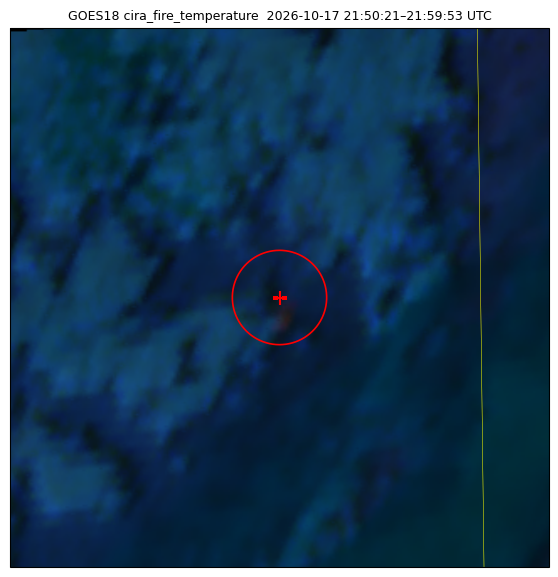

In [77]:
single_channel = "cira_fire_temperature" # "C07"
# single-channel cell if it has run with CHANNEL = <chan>, otherwise fetch it
if globals().get("CHANNEL") == single_channel and "chan" in globals():
    tc = chan
else:
    tc = gq.fetch_images(LAT, LON, START, END, single_channel, view_km=VIEW_KM, radius_km=RADIUS_KM,
                         sector=SECTOR, satellite=SATELLITE, mode=MODE)

overlays = [dict(mask=my_flag,   color="red",    label="my rule"),                 # pixel outlines
            dict(mask=noaa_fire, color="orange", label="NOAA fire", style="dot")]  # pixel centres

T = 11   # scan to show: an index, or a time like "2026-10-17 21:30"
gq.plot_image(tc, t=T)#, overlays=overlays)
plt.show()

In [ ]:
print("saved to", gq.save_images(tc, f"{OUT_DIR}/images", overlays=overlays, suffix="_flags"))

saved to output/images/goes18_true_color_F_52.825_-110.886_v80km_flags
